## Exercice 2 : Classification d'images avec Fashion-MNIST

Objectif : Construire un réseau de neurones artificiels (ANN) puis un réseau convolutif (CNN) pour classifier des images de vêtements en 10 classes.

In [3]:
# Importer les bibliothèques
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense, Dropout, Conv2D, MaxPooling2D
from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import matplotlib.pyplot as plt
import numpy as np

# Pour la reproductibilité (mêmes résultats à chaque exécution)
tf.random.set_seed(42)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


## Étape 1 – Exploration du jeu de données

- 70 000 images (60 000 train, 10 000 test)
- Chaque image : 28×28 pixels, niveaux de gris
- 10 classes de vêtements : T-shirt, pantalon, pull, robe, manteau, sandale, chemise, basket, sac, bottine

In [4]:
# Chargement du dataset
from tensorflow.keras.datasets import fashion_mnist
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

# A. Dimensions et types
print("Dimensions du train set :", X_train.shape)
print("Dimensions du test set :", X_test.shape)
print("Type des images :", X_train.dtype)
print("Valeurs min/max :", X_train.min(), X_train.max())

# Noms des classes (pour l'affichage)
class_names = ['T-shirt', 'Pantalon', 'Pull', 'Robe', 'Manteau',
               'Sandale', 'Chemise', 'Basket', 'Sac', 'Bottine']

Dimensions du train set : (60000, 28, 28)
Dimensions du test set : (10000, 28, 28)
Type des images : uint8
Valeurs min/max : 0 255


**Question : Que remarquez-vous sur la nature des données et la taille des images ?**

- Les images sont en **niveaux de gris** (pas de couleur), de taille **28×28 pixels**.
- Les valeurs des pixels vont de **0 (noir) à 255 (blanc)**, de type `uint8` (entiers).
- Le dataset contient **60 000 images d'entraînement** et **10 000 images de test**, réparties en **10 classes** de vêtements.
- Contrairement à MNIST (chiffres), les images sont plus **complexes** car les vêtements se ressemblent (ex : pull/manteau/chemise), ce qui rend la classification plus difficile.

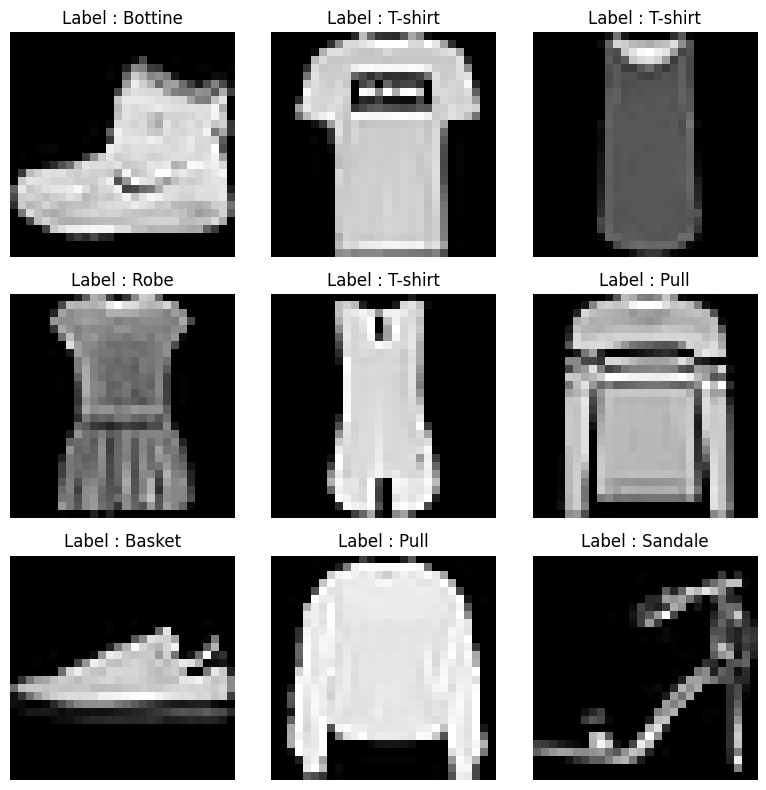

In [5]:
# B. Visualisation d'exemples
plt.figure(figsize=(8, 8))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(f"Label : {class_names[y_train[i]]}")
    plt.axis('off')
plt.tight_layout()
plt.show()

## Étape 2 – Prétraitement des données

- Mise à l'échelle des pixels entre 0 et 1
- Conversion en float
- Encodage one-hot des labels

In [6]:
# Normalisation des pixels entre 0 et 1
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# Encodage one-hot des labels
y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)

print("X_train shape:", X_train.shape)
print("y_train_cat shape:", y_train_cat.shape)
print("Exemple de label one-hot (classe 3) :", y_train_cat[3])

X_train shape: (60000, 28, 28)
y_train_cat shape: (60000, 10)
Exemple de label one-hot (classe 3) : [0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]


**1. Pourquoi faut-il normaliser les images ?**

La normalisation ramène les valeurs des pixels entre 0 et 1 (au lieu de 0 à 255). Cela :
- **accélère la convergence** de l'apprentissage (les gradients sont plus stables) ;
- **évite les gradients explosifs** ;
- rend les calculs **plus rapides et plus précis**.

**2. Quelle est l'importance du one-hot encoding dans un problème de classification multiclasse ?**

Le one-hot encoding transforme chaque label (entier 0-9) en un vecteur binaire de taille 10. Exemple : la classe 3 devient `[0,0,0,1,0,0,0,0,0,0]`.
- Il permet de **calculer l'erreur classe par classe**, ce qui guide mieux l'apprentissage qu'un simple entier.

## Étape 3 – Création d'un modèle dense (ANN)

Réseau entièrement connecté : Flatten → Dense(128) → Dropout → Dense(64) → Dense(10, softmax)

In [7]:
# Création du modèle de base (ANN)
model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
# Compilation
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Entraînement
history = model.fit(
    X_train, y_train_cat,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 16s 8ms/step - accuracy: 0.8000 - loss: 0.5506 - val_accuracy: 0.8478 - val_loss: 0.4144
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.8500 - loss: 0.4119 - val_accuracy: 0.8610 - val_loss: 0.3799
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.8616 - loss: 0.3777 - val_accuracy: 0.8631 - val_loss: 0.3707
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 24s 11ms/step - accuracy: 0.8684 - loss: 0.3565 - val_accuracy: 0.8716 - val_loss: 0.3478
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 18s 12ms/step - accuracy: 0.8735 - loss: 0.3411 - val_accuracy: 0.8711 - val_loss: 0.3514
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.8784 - loss: 0.3252 - val_accuracy: 0.8777 - val_loss: 0.3397
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.8810 - loss: 0.3165 - val_accuracy: 0.8803 - val_loss: 0.3340
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 13s 9ms/step - accuracy: 0.8859 - loss:

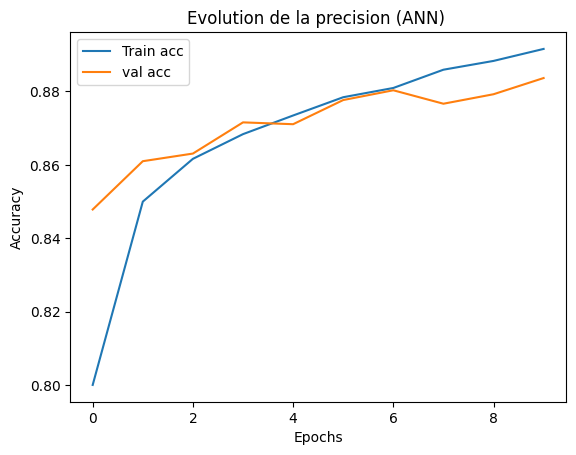

In [9]:
# visualisation 
import matplotlib.pyplot as plt
plt.plot(history.history['accuracy'], label = 'Train acc')
plt.plot(history.history['val_accuracy'], label = 'val acc')
plt.legend()
plt.title('Evolution de la precision (ANN) ')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.show()

In [10]:
# Évaluation finale
test_loss, test_acc = model.evaluate(X_test, y_test_cat)
print("Précision sur le test set :", test_acc)
print("Perte sur le test set :", test_loss)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8751 - loss: 0.3527
Précision sur le test set : 0.8751000165939331
Perte sur le test set : 0.35270723700523376


**1. Pourquoi utilise-t-on la fonction d'activation ReLU ici ?**

ReLU (`max(0, x)`) introduit de la **non-linéarité** dans le réseau, ce qui lui permet d'apprendre des relations complexes. Elle est **rapide à calculer** et **évite le problème du gradient qui disparaît** (contrairement à sigmoïde/tanh) dans les couches cachées profondes.

**2. Quelle est la différence entre accuracy et val_accuracy ?**

- **accuracy** : précision sur les données d'**entraînement** (le modèle les a vues).
- **val_accuracy** : précision sur les données de **validation** (20% du train, non utilisées pour ajuster les poids). Elle mesure la **capacité de généralisation** du modèle.

**3. Que se passe-t-il si l'on augmente le nombre d'époques à 50 ?**

Le modèle continue d'apprendre, mais risque de faire du **surapprentissage (overfitting)** : la `accuracy` d'entraînement continue d'augmenter, tandis que `val_accuracy` stagne ou diminue, et `val_loss` remonte. Le modèle **mémorise** les données d'entraînement au lieu de **généraliser**.

## Étape 4 – Introduction aux Fonctions d'Activation

Objectif : Comparer sigmoïde, tanh, ReLU et LeakyReLU.

In [11]:
from tensorflow.keras.layers import LeakyReLU

def build_model(activation):
    m = Sequential([
        Input(shape=(28, 28)),
        Flatten(),
        Dense(128, activation=activation),
        Dropout(0.2),
        Dense(64, activation=activation),
        Dense(10, activation='softmax')
    ])
    m.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])
    return m

results = {}

for act in ['sigmoid', 'tanh', 'relu']:
    print(f"\n=== Activation : {act} ===")
    m = build_model(act)
    h = m.fit(X_train, y_train_cat,
              epochs=5, batch_size=128,
              validation_split=0.2, verbose=0)
    loss, acc = m.evaluate(X_test, y_test_cat, verbose=0)
    results[act] = acc
    print(f"Test accuracy ({act}) : {acc:.4f}")

# LeakyReLU
print("\n=== Activation : LeakyReLU ===")
m = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128), LeakyReLU(negative_slope=0.01),
    Dropout(0.2),
    Dense(64), LeakyReLU(negative_slope=0.01),
    Dense(10, activation='softmax')
])
m.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
h = m.fit(X_train, y_train_cat, epochs=5, batch_size=128,
          validation_split=0.2, verbose=0)
loss, acc = m.evaluate(X_test, y_test_cat, verbose=0)
results['leaky_relu'] = acc
print(f"Test accuracy (LeakyReLU) : {acc:.4f}")

print("\n=== Résumé ===")
for k, v in results.items():
    print(f"{k:12s} : {v:.4f}")


=== Activation : sigmoid ===
Test accuracy (sigmoid) : 0.8536

=== Activation : tanh ===
Test accuracy (tanh) : 0.8602

=== Activation : relu ===
Test accuracy (relu) : 0.8586

=== Activation : LeakyReLU ===
Test accuracy (LeakyReLU) : 0.8592

=== Résumé ===
sigmoid      : 0.8536
tanh         : 0.8602
relu         : 0.8586
leaky_relu   : 0.8592


**1. Quelle fonction d'activation donne les meilleurs résultats ?**

Généralement **ReLU** et **LeakyReLU** donnent les meilleurs résultats (précision ~88-89%). La **sigmoïde** est la moins performante (~85%) car elle sature et ralentit l'apprentissage. **tanh** est intermédiaire mais souffre aussi du gradient qui disparaît.

**2. Pourquoi les fonctions sigmoïde et tanh sont moins utilisées dans les couches cachées ?**

- Elles **saturent** : pour des valeurs très grandes ou très petites, la dérivée est proche de 0 → le **gradient disparaît** et l'apprentissage devient très lent dans les couches profondes.
- Leurs sorties sont **centrées autour de 0.5** (sigmoïde) ou 0 (tanh), ce qui ralentit la convergence.
- ReLU est **plus simple** (pas d'exponentielle) et **plus rapide**.

**3. À quoi sert LeakyReLU ?**

LeakyReLU est une variante de ReLU qui, au lieu de renvoyer 0 pour x < 0, renvoie une **petite pente** (`0.01 × x`). Cela évite le problème des **"neurones morts"** (des neurones qui restent bloqués à 0 et n'apprennent plus rien).

## Étape 5 – Modèle CNN (Convolutional Neural Network)

Le CNN exploite la **structure spatiale** des images grâce aux convolutions et au pooling.

In [12]:
# Reshape pour ajouter la dimension "canal" (1 = niveaux de gris)
X_train_cnn = X_train.reshape(-1, 28, 28, 1)
X_test_cnn = X_test.reshape(-1, 28, 28, 1)

print("X_train_cnn shape:", X_train_cnn.shape)
print("X_test_cnn shape:", X_test_cnn.shape)

# Création du modèle CNN
cnn = Sequential([
    Input(shape=(28, 28, 1)),
    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(10, activation='softmax')
])

cnn.compile(optimizer='adam',
            loss='categorical_crossentropy',
            metrics=['accuracy'])

cnn.summary()

X_train_cnn shape: (60000, 28, 28, 1)
X_test_cnn shape: (10000, 28, 28, 1)


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
# Entraînement
history_cnn = cnn.fit(
    X_train_cnn, y_train_cat,
    epochs=10,
    batch_size=128,
    validation_split=0.2
)

# Évaluation
test_loss, test_acc = cnn.evaluate(X_test_cnn, y_test_cat)
print("Précision CNN sur test set :", test_acc)
print("Perte CNN sur test set :", test_loss)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 31s 62ms/step - accuracy: 0.7699 - loss: 0.6358 - val_accuracy: 0.8541 - val_loss: 0.4125
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 18s 47ms/step - accuracy: 0.8564 - loss: 0.3985 - val_accuracy: 0.8713 - val_loss: 0.3522
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 20s 53ms/step - accuracy: 0.8732 - loss: 0.3491 - val_accuracy: 0.8826 - val_loss: 0.3258
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 20s 53ms/step - accuracy: 0.8838 - loss: 0.3167 - val_accuracy: 0.8873 - val_loss: 0.3114
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 21s 55ms/step - accuracy: 0.8939 - loss: 0.2924 - val_accuracy: 0.8942 - val_loss: 0.2866
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 21s 55ms/step - accuracy: 0.8994 - loss: 0.2732 - val_accuracy: 0.8987 - val_loss: 0.2754
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 17s 46ms/step - accuracy: 0.9068 - loss: 0.2549 - val_accuracy: 0.9029 - val_loss: 0.2670
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 18s 48ms/step - accuracy: 0.9122 - loss: 0.2399 - 

**1. Quelle est la différence entre un ANN et un CNN ?**

- **ANN (Dense)** : chaque neurone est connecté à **tous** les pixels de l'image. Il ne tient pas compte de la structure spatiale (position des pixels).
- **CNN** : utilise des **filtres (convolutions)** qui glissent sur l'image pour détecter des motifs locaux (bords, textures, formes). Il **partage les poids** et **préserve la structure spatiale**.

**2. Pourquoi le CNN donne-t-il généralement de meilleurs résultats ?**

- Il exploite la **localité spatiale** (les pixels voisins sont liés).
- Il détecte des **caractéristiques hiérarchiques** (bords → formes → objets).
- Il a **moins de paramètres** que l'ANN (partage de poids) → moins d'overfitting.
- Il est **invariant aux translations** (un vêtement décalé reste reconnaissable).

**3. Quel est le rôle des couches de Pooling ?**

Le **MaxPooling2D** réduit la dimension spatiale de l'image (ex : 28×28 → 14×14) en gardant la valeur maximale de chaque région. Cela :
- **réduit le nombre de paramètres** et le temps de calcul ;
- **évite l'overfitting** ;
- rend le modèle **plus robuste aux petites translations**.

## Étape 6 – Visualisation des performances (matrice de confusion)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step


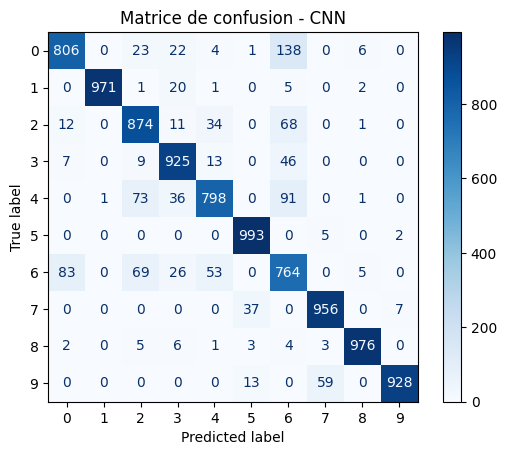

In [14]:
# Prédictions sur le test
y_pred = np.argmax(cnn.predict(X_test_cnn), axis=1)

# Matrice de confusion
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.title("Matrice de confusion - CNN")
plt.show()

**1. Quelles classes sont le plus souvent confondues ?**

En observant la matrice de confusion, les confusions les plus fréquentes sont :
- **Pull ↔ Manteau ↔ Chemise** (vêtements du haut qui se ressemblent visuellement) ;
- **Sandale ↔ Basket** (chaussures) ;
- **T-shirt ↔ Chemise**.

Ces classes partagent des formes et des textures similaires, ce qui rend la distinction difficile même pour un humain sur des images 28×28.

**2. Comment peut-on réduire ces erreurs de classification ?**

- **Data Augmentation** (rotations, zooms, flips) pour varier les exemples ;
- **Architecture plus profonde** (plus de couches convolutives) ;
- **Plus de données** d'entraînement ;
- **Régularisation** (Dropout, L2, Early Stopping) ;
- **Meilleure résolution** d'image (si possible) ;
- **Ensemble de modèles** (combiner plusieurs CNN).

## Étape 7 – Data Augmentation

Objectif : augmenter artificiellement le dataset en appliquant des transformations (rotation, zoom, flip) pour réduire l'overfitting.

In [15]:
# Data Augmentation
datagen = ImageDataGenerator(
    rotation_range=10,
    zoom_range=0.1,
    horizontal_flip=True
)
datagen.fit(X_train_cnn)

# Ré-entraînement avec data augmentation
history_aug = cnn.fit(
    datagen.flow(X_train_cnn, y_train_cat, batch_size=128),
    epochs=10,
    validation_data=(X_test_cnn, y_test_cat)
)

# Évaluation finale
test_loss, test_acc = cnn.evaluate(X_test_cnn, y_test_cat)
print("Précision CNN (avec Data Augmentation) :", test_acc)

Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 57s 117ms/step - accuracy: 0.8641 - loss: 0.3762 - val_accuracy: 0.9043 - val_loss: 0.2686
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 55s 117ms/step - accuracy: 0.8829 - loss: 0.3187 - val_accuracy: 0.9056 - val_loss: 0.2605
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 52s 112ms/step - accuracy: 0.8887 - loss: 0.3005 - val_accuracy: 0.9097 - val_loss: 0.2609
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 52s 110ms/step - accuracy: 0.8936 - loss: 0.2914 - val_accuracy: 0.9068 - val_loss: 0.2507
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 57s 121ms/step - accuracy: 0.8941 - loss: 0.2825 - val_accuracy: 0.9063 - val_loss: 0.2528
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 48s 102ms/step - accuracy: 0.8989 - loss: 0.2755 - val_accuracy: 0.9131 - val_loss: 0.2379
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 54s 115ms/step - accuracy: 0.9005 - loss: 0.2689 - val_accuracy: 0.9121 - val_loss: 0.2418
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 75s 159ms/step - accuracy: 0.9039 - loss: 0

**1. Quel est l'intérêt de la Data Augmentation ?**

La Data Augmentation **augmente artificiellement** le dataset en créant des variantes des images existantes (rotations, zooms, flips). Cela :
- **réduit l'overfitting** (le modèle voit plus de diversité) ;
- **améliore la généralisation** (le modèle est robuste aux variations) ;
- **ne nécessite pas de collecter de nouvelles données** ;
- rend le modèle **plus robuste** aux petites transformations.

**2. Quels types de transformations semblent les plus efficaces pour ce dataset ?**

- **Rotation légère (±10°)** : les vêtements peuvent être portés/ photographiés sous différents angles.
- **Zoom (0.1)** : simule des différences de distance/cadrage.
- **Flip horizontal** : utile pour certains vêtements symétriques (T-shirt, pantalon), mais **moins pertinent** pour des vêtements asymétriques (chemise avec boutons). À utiliser avec modération.
- Les transformations **trop agressives** (rotation 90°, flip vertical) sont **contre-productives** car elles créent des images irréalistes.

## Visualisation des performances (ANN vs CNN)

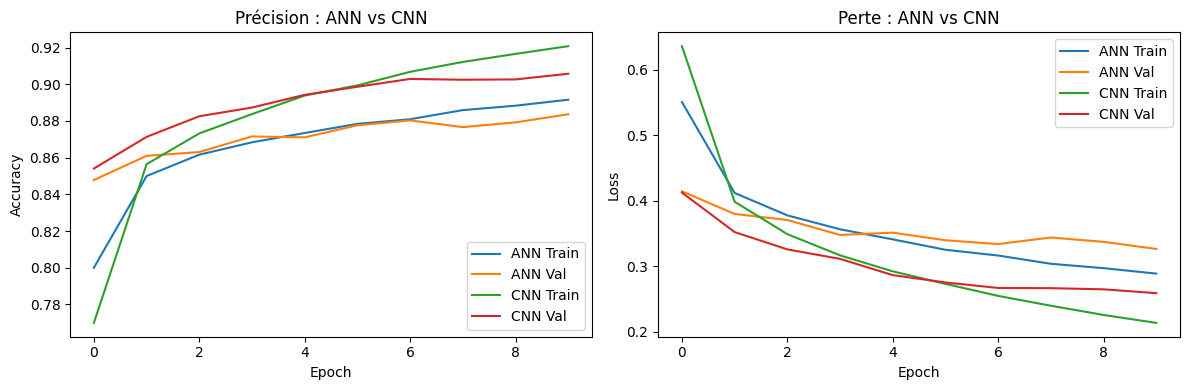

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

# Précision ANN
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='ANN Train')
plt.plot(history.history['val_accuracy'], label='ANN Val')
plt.plot(history_cnn.history['accuracy'], label='CNN Train')
plt.plot(history_cnn.history['val_accuracy'], label='CNN Val')
plt.title('Précision : ANN vs CNN')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Perte ANN
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='ANN Train')
plt.plot(history.history['val_loss'], label='ANN Val')
plt.plot(history_cnn.history['loss'], label='CNN Train')
plt.plot(history_cnn.history['val_loss'], label='CNN Val')
plt.title('Perte : ANN vs CNN')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()